In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OneHotEncoder,LabelEncoder

from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier,plot_tree


from sklearn.metrics import accuracy_score, confusion_matrix, classification_report,precision_score,f1_score,recall_score

pd.set_option('display.max_columns',None)

In [2]:
data_path='/content/sample_data/WA_Fn-UseC_-Telco-Customer-Churn.csv'
df=pd.read_csv(data_path)

In [3]:
df.shape

(7043, 21)

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [6]:
df.describe(include='object').T

,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


In [7]:
df.isna().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df['SeniorCitizen'].value_counts()

,count
SeniorCitizen,
0,5901
1,1142


In [10]:
cat_cols=df.select_dtypes(include='object').columns
for col in df.columns:
  print(f'{col} --> {df[col].unique()}')

customerID --> ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
gender --> ['Female' 'Male']
SeniorCitizen --> [0 1]
Partner --> ['Yes' 'No']
Dependents --> ['No' 'Yes']
tenure --> [ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]
PhoneService --> ['No' 'Yes']
MultipleLines --> ['No phone service' 'No' 'Yes']
InternetService --> ['DSL' 'Fiber optic' 'No']
OnlineSecurity --> ['No' 'Yes' 'No internet service']
OnlineBackup --> ['Yes' 'No' 'No internet service']
DeviceProtection --> ['No' 'Yes' 'No internet service']
TechSupport --> ['No' 'Yes' 'No internet service']
StreamingTV --> ['No' 'Yes' 'No internet service']
StreamingMovies --> ['No' 'Yes' 'No internet service']
Contract --> ['Month-to-month' 'One year' 'Two year']
PaperlessBilling --> ['Yes' 'No']
PaymentMethod --> ['Elect

In [11]:
(df['TotalCharges']==' ').sum()

np.int64(11)

In [12]:
df['TotalCharges']=df['TotalCharges'].replace(' ',np.nan)

In [13]:
df['TotalCharges']=df['TotalCharges'].astype(float)


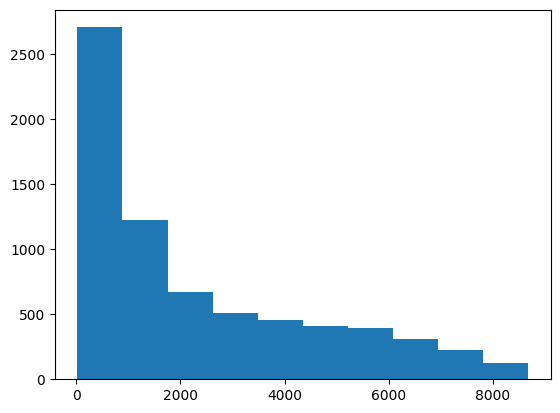

In [14]:
plt.hist(df['TotalCharges'])
plt.show()

In [15]:
df['TotalCharges'].isna().sum()

np.int64(11)

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


#Train test split

In [17]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [18]:
X,y = df.drop(['customerID','Churn'],axis=1),df['Churn']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [19]:
median_value = X_train['TotalCharges'].median()
X_train['TotalCharges'] = X_train['TotalCharges'].fillna(median_value)
X_test['TotalCharges'] = X_test['TotalCharges'].fillna(median_value)

In [20]:
scale_cols=['MonthlyCharges','TotalCharges','tenure']

In [21]:
scaler = StandardScaler()

X_train_scale=pd.DataFrame(
  scaler.fit_transform(X_train[scale_cols]),
  columns=scale_cols,
  index=X_train.index
)
X_test_scale=pd.DataFrame(
  scaler.transform(X_test[scale_cols]),
  columns=scale_cols,
  index=X_test.index
)

In [22]:
cat_cols=X_train.select_dtypes(include='object').columns
one_hot_encoder=OneHotEncoder(sparse_output=False,handle_unknown='ignore')
X_train_encode=one_hot_encoder.fit_transform(X_train[cat_cols])
X_test_encode=one_hot_encoder.transform(X_test[cat_cols])

column_names=one_hot_encoder.get_feature_names_out(cat_cols)

X_train_encode=pd.DataFrame(
    X_train_encode,
    columns=column_names,
    index=X_train.index
)

X_test_encode=pd.DataFrame(
    X_test_encode,
    columns=column_names,
    index=X_test.index
)

In [23]:
X_train_final=pd.concat([X_train_scale,X_train_encode,X_train['SeniorCitizen']],axis=1)
X_test_final=pd.concat([X_test_scale,X_test_encode,X_test['SeniorCitizen']],axis=1)


In [24]:
label_encoder=LabelEncoder()
y_train_final=pd.Series(label_encoder.fit_transform(y_train),index=y_train.index)
y_test_final=pd.Series(label_encoder.transform(y_test),index=y_test.index)

In [25]:
smote = SMOTE(random_state=42)
X_train_balanced,y_train_balanced = smote.fit_resample(X_train_final,y_train_final)

In [26]:
y_train_balanced.value_counts()

,count
0,4139
1,4139


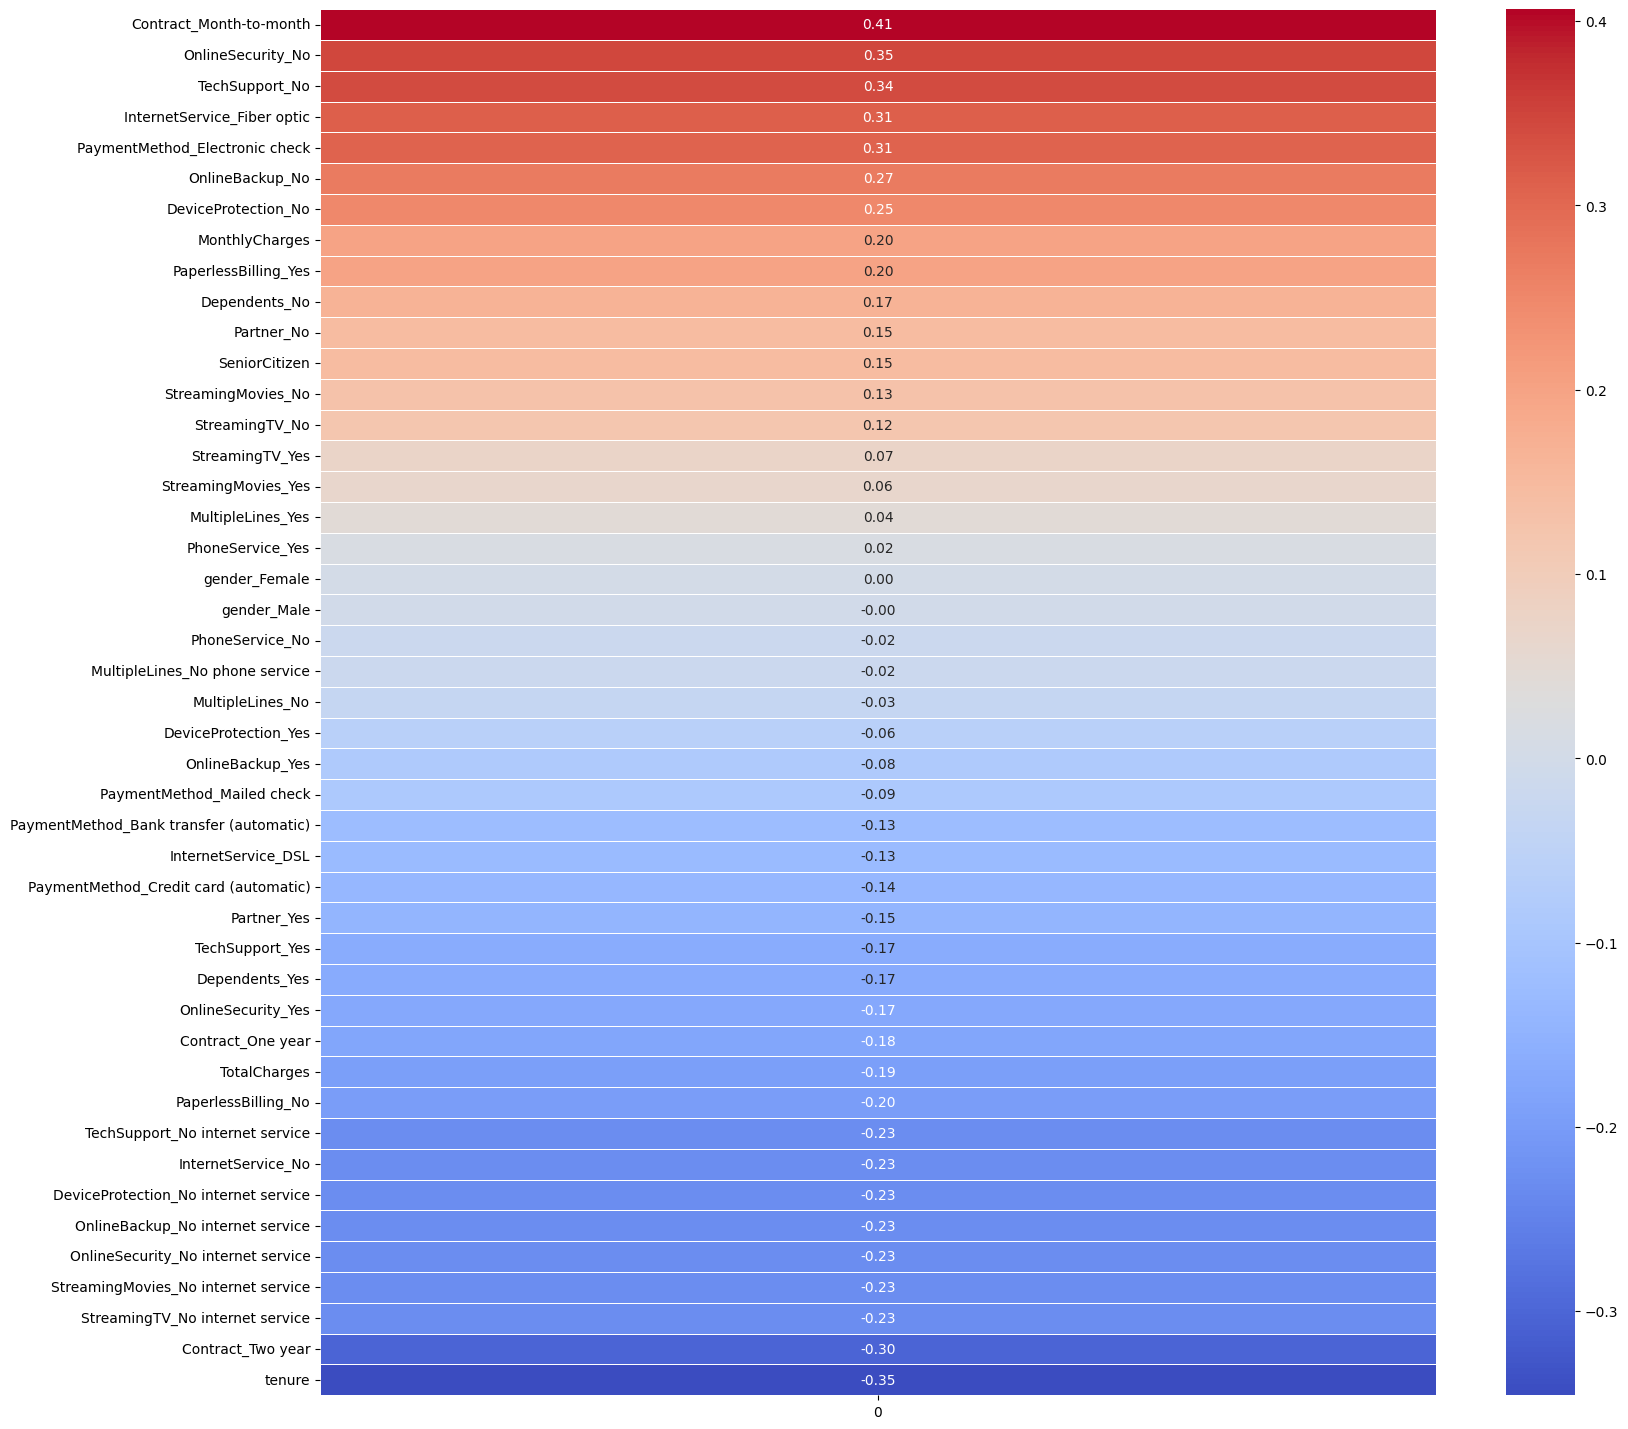

In [27]:
corr=X_train_final.corrwith(y_train_final).sort_values(ascending=False).to_frame()

plt.figure(figsize=(18,18))
sns.heatmap(corr,annot=True,linewidth=0.5,fmt='.2f',cmap='coolwarm')
plt.show()

In [28]:
X_train.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges'],
      dtype='object')

In [29]:
selected_cols=['OnlineBackup_No','tenure', 'Contract_Month-to-month']

In [30]:
X_train_selected=X_train_balanced[selected_cols]
X_test_selected=X_test_final[selected_cols]


Accuracy Score: 0.6706884315117104
Confusion Matrix
[[625 410]
 [ 54 320]]
Classification Report
              precision    recall  f1-score   support

           0       0.92      0.60      0.73      1035
           1       0.44      0.86      0.58       374

    accuracy                           0.67      1409
   macro avg       0.68      0.73      0.65      1409
weighted avg       0.79      0.67      0.69      1409



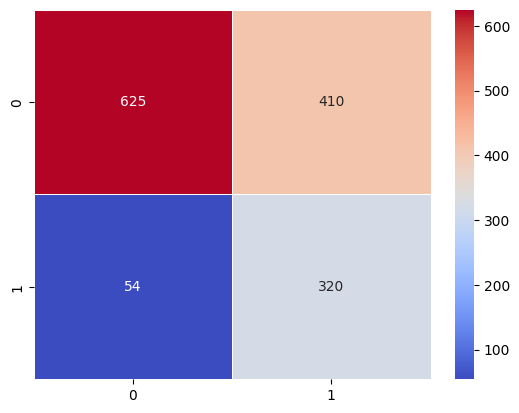

In [31]:
log_reg=LogisticRegression()
log_reg.fit(X_train_selected,y_train_balanced)
log_reg_pred=log_reg.predict(X_test_selected)

print('Accuracy Score:', accuracy_score(y_test_final, log_reg_pred))

print('Confusion Matrix')
print(confusion_matrix(y_test_final, log_reg_pred))

print('Classification Report')
print(classification_report(y_test_final, log_reg_pred))

sns.heatmap(
    confusion_matrix(y_test_final, log_reg_pred),
    annot=True,
    fmt='d',
    linewidths=0.5,
    cmap='coolwarm'
)
plt.show()

Accuracy Score: 0.7288857345635202
Confusion Matrix
[[889 146]
 [236 138]]
Classification Report
              precision    recall  f1-score   support

           0       0.79      0.86      0.82      1035
           1       0.49      0.37      0.42       374

    accuracy                           0.73      1409
   macro avg       0.64      0.61      0.62      1409
weighted avg       0.71      0.73      0.72      1409



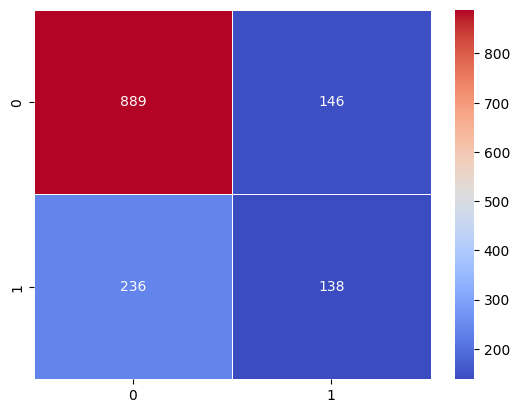

In [32]:
knn = KNeighborsClassifier(n_neighbors=17)
knn.fit(X_train_selected,y_train_balanced)
knn_pred=knn.predict(X_test_selected)

print('Accuracy Score:', accuracy_score(y_test_final, knn_pred))

print('Confusion Matrix')
print(confusion_matrix(y_test_final, knn_pred))

print('Classification Report')
print(classification_report(y_test_final, knn_pred))

sns.heatmap(
    confusion_matrix(y_test_final, knn_pred),
    annot=True,
    fmt='d',
    linewidths=0.5,
    cmap='coolwarm'
)
plt.show()

In [33]:
print("Actual values:")
print(y_test_final.value_counts())

print("Predicted values:")
print(pd.Series(knn_pred).value_counts())

Actual values:
0    1035
1     374
Name: count, dtype: int64
Predicted values:
0    1125
1     284
Name: count, dtype: int64


In [34]:
print(label_encoder.classes_)

['No' 'Yes']


In [35]:
print("Actual values:")
print(y_test_final.value_counts())

print("Predicted values:")
print(pd.Series(log_reg_pred).value_counts())

Actual values:
0    1035
1     374
Name: count, dtype: int64
Predicted values:
1    730
0    679
Name: count, dtype: int64


In [36]:
# Get probability of Churn (class 1)
y_prob = log_reg.predict_proba(X_test_selected)[:, 1]

thresholds = [0.3, 0.5, 0.7]

for threshold in thresholds:

    y_pred_threshold = (y_prob >= threshold).astype(int)

    print("\nThreshold:", threshold)

    print("Accuracy:", accuracy_score(y_test_final, y_pred_threshold))
    print("Precision:", precision_score(y_test_final, y_pred_threshold))
    print("Recall:", recall_score(y_test_final, y_pred_threshold))
    print("F1 Score:", f1_score(y_test_final, y_pred_threshold))


Threshold: 0.3
Accuracy: 0.6501064584811923
Precision: 0.4240102171136654
Recall: 0.8877005347593583
F1 Score: 0.5738980121002593

Threshold: 0.5
Accuracy: 0.6706884315117104
Precision: 0.4383561643835616
Recall: 0.8556149732620321
F1 Score: 0.5797101449275363

Threshold: 0.7
Accuracy: 0.7601135557132718
Precision: 0.545
Recall: 0.5828877005347594
F1 Score: 0.5633074935400517


Lowering the threshold boosts recall: Classifying more customers as potential churners increases recall.

Peak recall at 0.3: This threshold reaches the highest recall at 88.50%.

Trade-off at 0.7: Precision and accuracy rise, while recall drops sharply.

Best balance at 0.5: This threshold delivers the highest F1-score (58.08%), balancing precision and recall best among the tested values.

In [37]:
comparison_df = pd.DataFrame({
    'Model': ['KNN', 'Logistic Regression'],
    'Accuracy': [
        accuracy_score(y_test_final, knn_pred),
        accuracy_score(y_test_final, log_reg_pred)
    ],
    'Precision': [
        precision_score(y_test_final, knn_pred),
        precision_score(y_test_final, log_reg_pred)
    ],
    'Recall': [
        recall_score(y_test_final, knn_pred),
        recall_score(y_test_final, log_reg_pred)
    ],
    'F1 Score': [
        f1_score(y_test_final, knn_pred),
        f1_score(y_test_final, log_reg_pred)
    ]
})

comparison_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.7289,0.4859,0.3690,0.4195
1,Logistic Regression,0.6707,0.4384,0.8556,0.5797


### Model Comparison
KNN performance: Reaches higher accuracy (72.89%) and precision (48.59%), but low recall (36.90%) leaves many actual churners undetected.

Logistic Regression performance: Reaches higher recall (85.56%) and F1-score (57.97%), capturing far more true churn cases despite lower accuracy and precision.

Model selection: Logistic Regression fits churn prediction better because catching at-risk customers supports early retention actions.

### False Positives and False Negatives

False positives: Wasted retention spend on customers who would have stayed anyway.

False negatives: Missed churners, risking lost customers and future revenue.

Cost and recall trade-off: Higher recall helps catch more potential churners, even with extra false positives, because missed churn is often costlier.

Model takeaway: Logistic Regression offers much higher recall than KNN, making it more effective for spotting at-risk customers.

In [38]:
depth_values = [3, 5, 10, None]

tree_results = []
tree_models = {}
tree_predictions = {}

for depth in depth_values:

    decision_tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    # Train the model
    decision_tree.fit(
        X_train_selected,
        y_train_balanced
    )

    # Predict using test data
    tree_pred = decision_tree.predict(X_test_selected)

    # Store model and predictions
    tree_models[depth] = decision_tree
    tree_predictions[depth] = tree_pred

    # Calculate evaluation metrics
    tree_results.append({
        'max_depth': str(depth),
        'Accuracy': accuracy_score(y_test_final, tree_pred),
        'Precision': precision_score(y_test_final, tree_pred),
        'Recall': recall_score(y_test_final, tree_pred),
        'F1 Score': f1_score(y_test_final, tree_pred)
    })

tree_results_df = pd.DataFrame(tree_results)

tree_results_df.round(4)

,max_depth,Accuracy,Precision,Recall,F1 Score
0,3,0.6529,0.4256,0.8797,0.5737
1,5,0.6565,0.4274,0.8663,0.5724
2,10,0.6828,0.4423,0.7487,0.5561
3,None,0.7622,0.5582,0.5000,0.5275


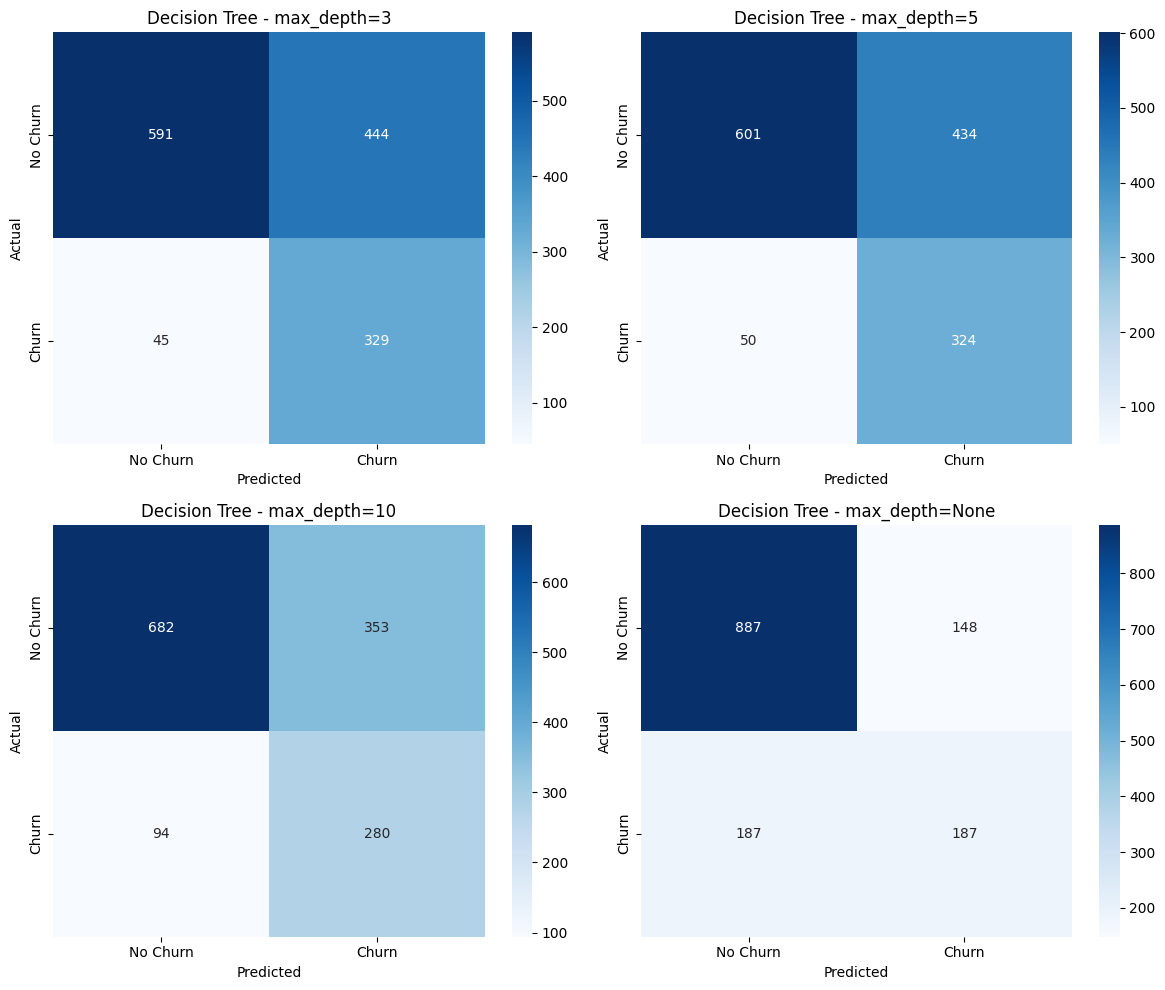

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, depth in zip(axes.flatten(), depth_values):

    cm = confusion_matrix(
        y_test_final,
        tree_predictions[depth]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax
    )

    ax.set_title(f'Decision Tree - max_depth={depth}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_xticklabels(['No Churn', 'Churn'])
    ax.set_yticklabels(['No Churn', 'Churn'])

plt.tight_layout()
plt.show()

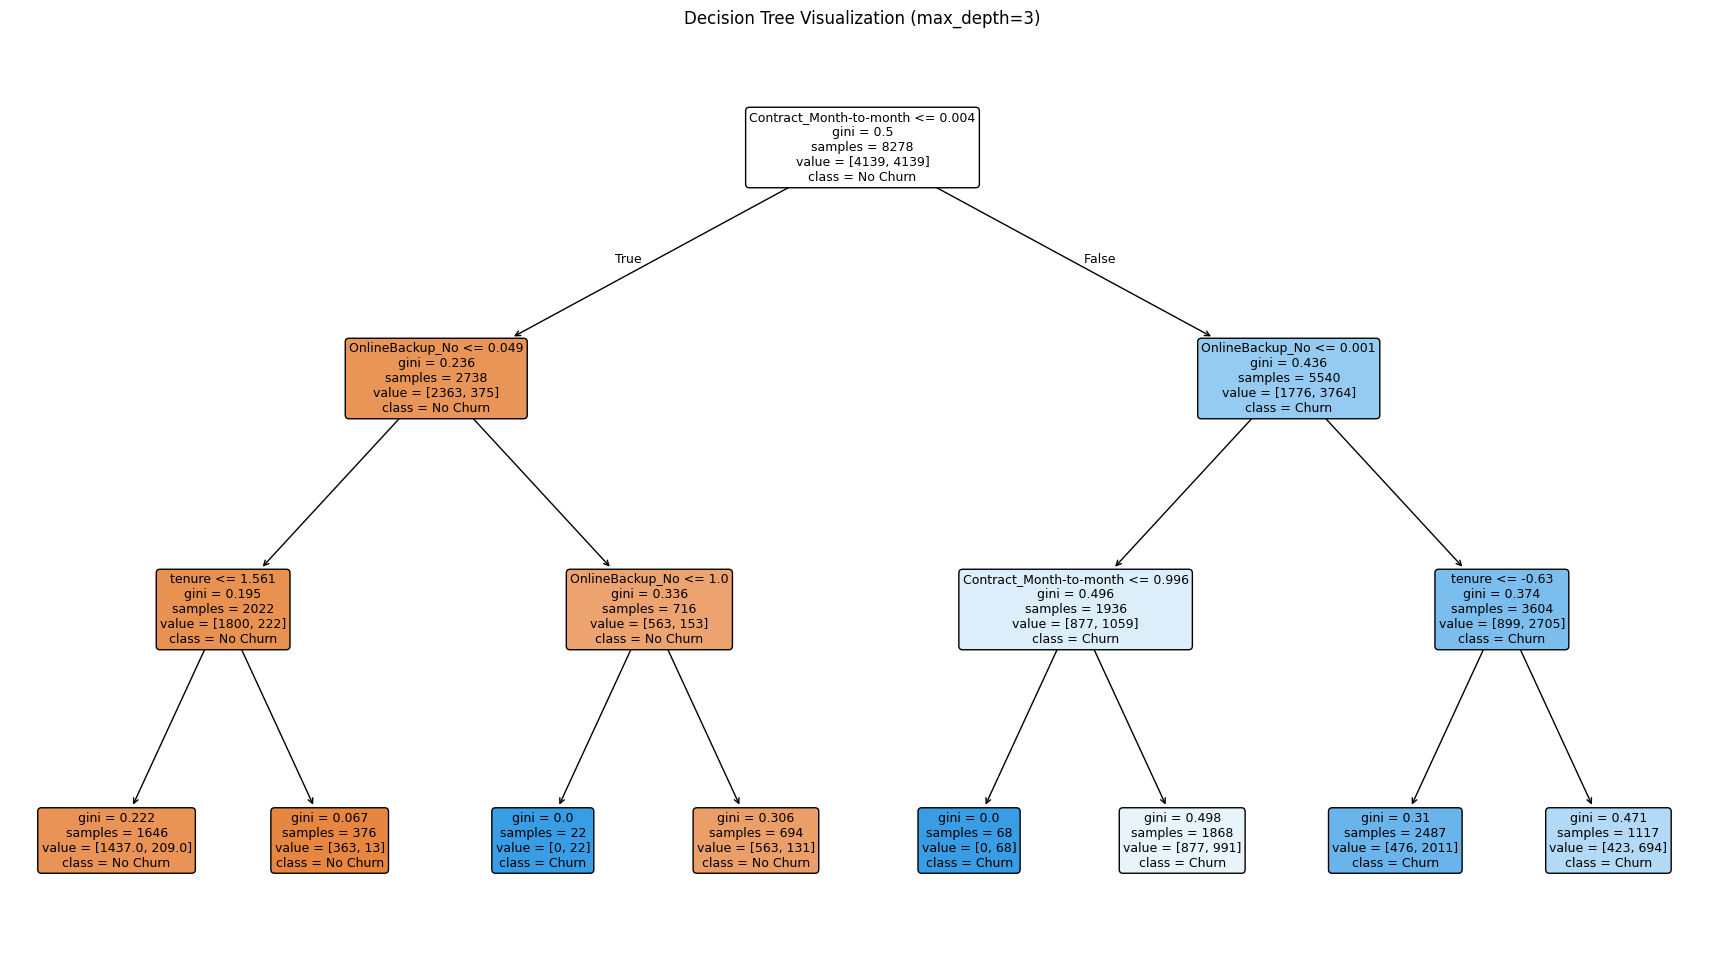

In [40]:
plt.figure(figsize=(22, 12))

plot_tree(
    tree_models[3],
    feature_names=selected_cols,
    class_names=['No Churn', 'Churn'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('Decision Tree Visualization (max_depth=3)')
plt.show()

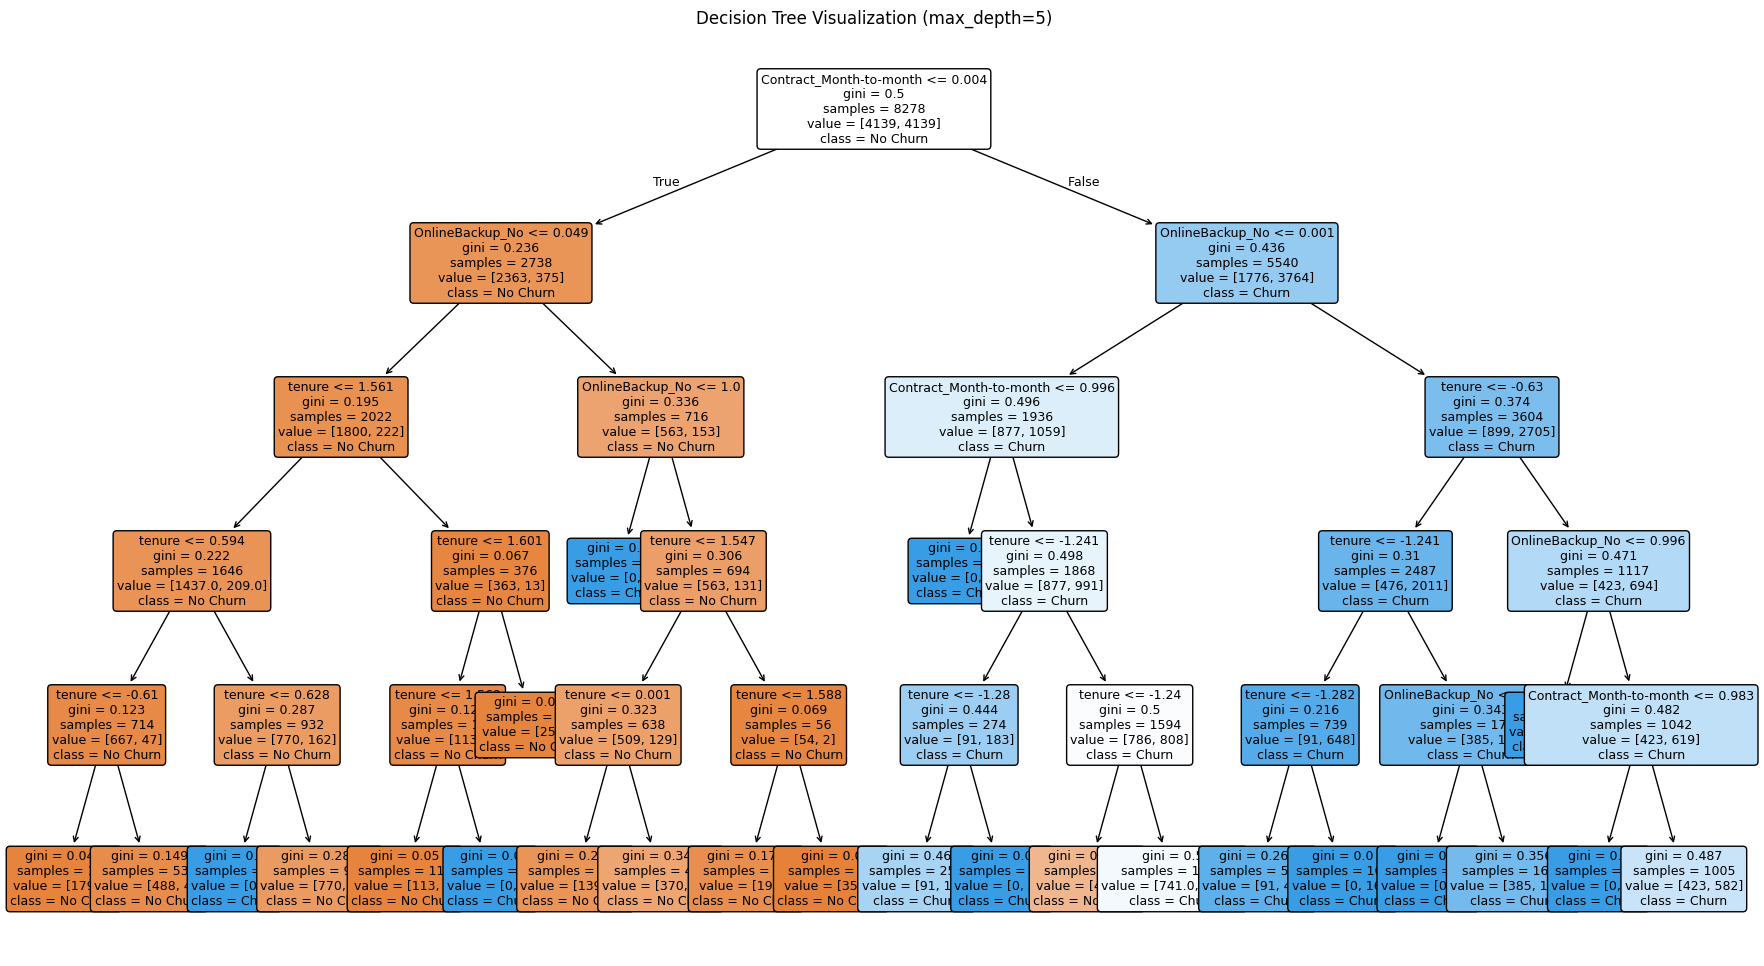

In [41]:
plt.figure(figsize=(22, 12))

plot_tree(
    tree_models[5],
    feature_names=selected_cols,
    class_names=['No Churn', 'Churn'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('Decision Tree Visualization (max_depth=5)')
plt.show()

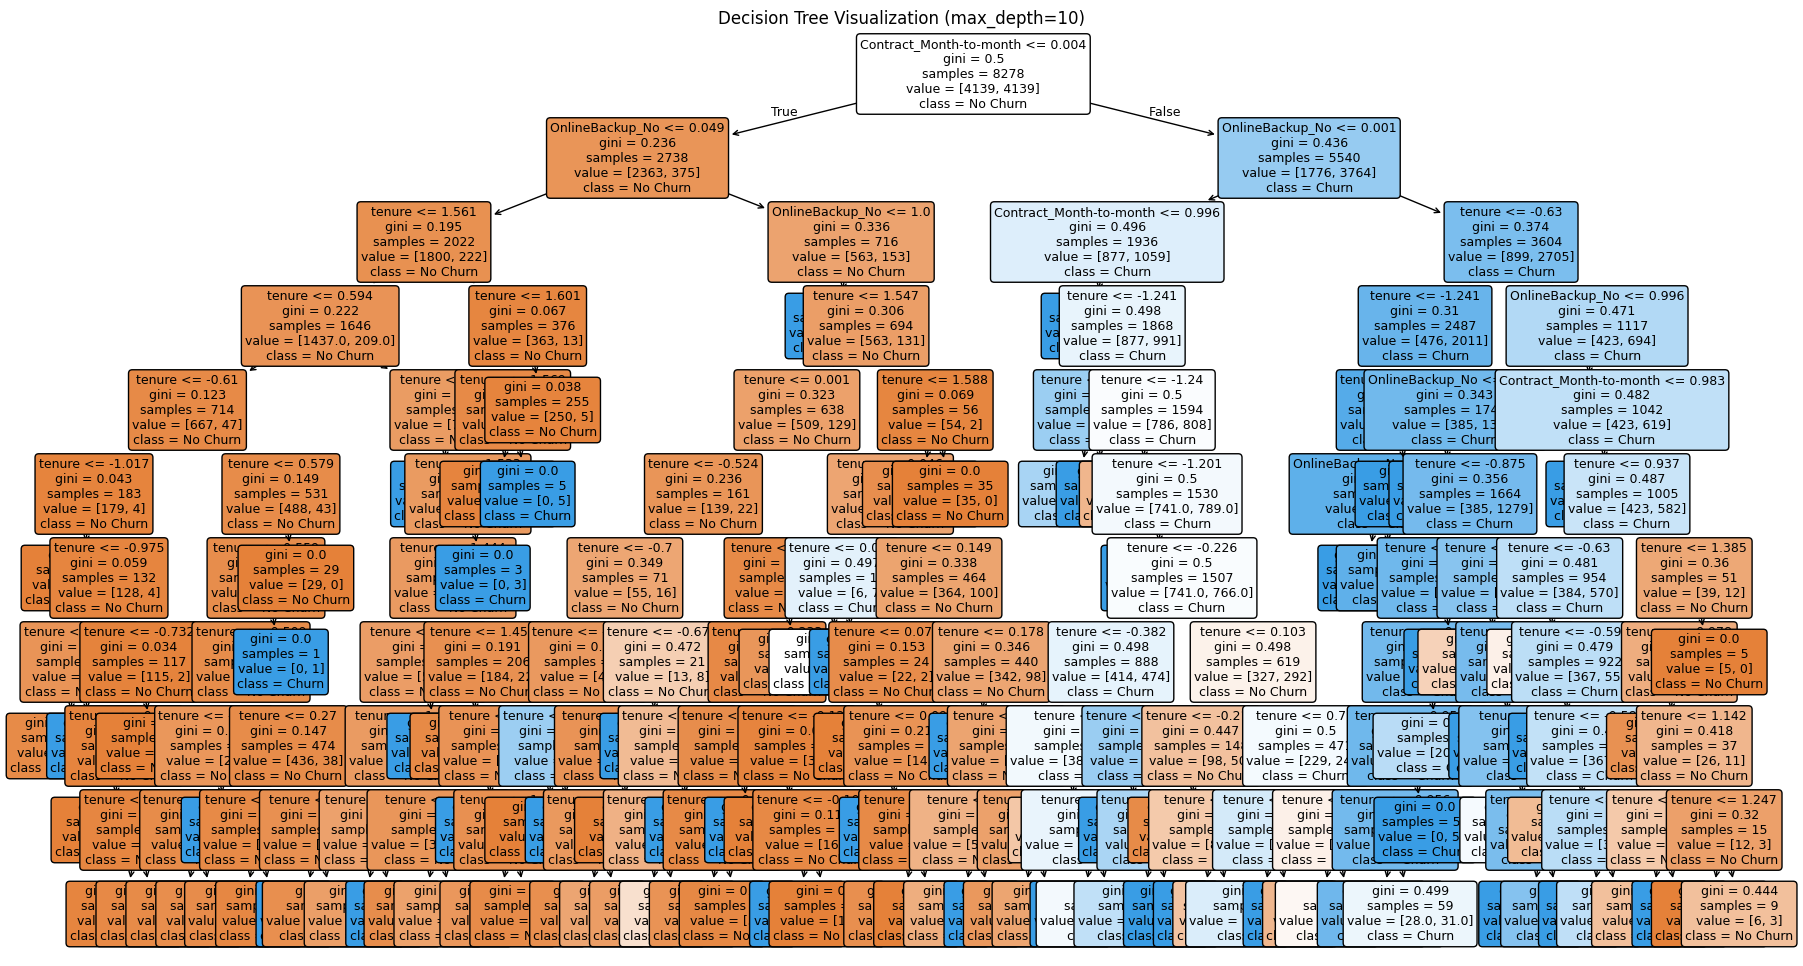

In [42]:
plt.figure(figsize=(22, 12))

plot_tree(
    tree_models[10],
    feature_names=selected_cols,
    class_names=['No Churn', 'Churn'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('Decision Tree Visualization (max_depth=10)')
plt.show()

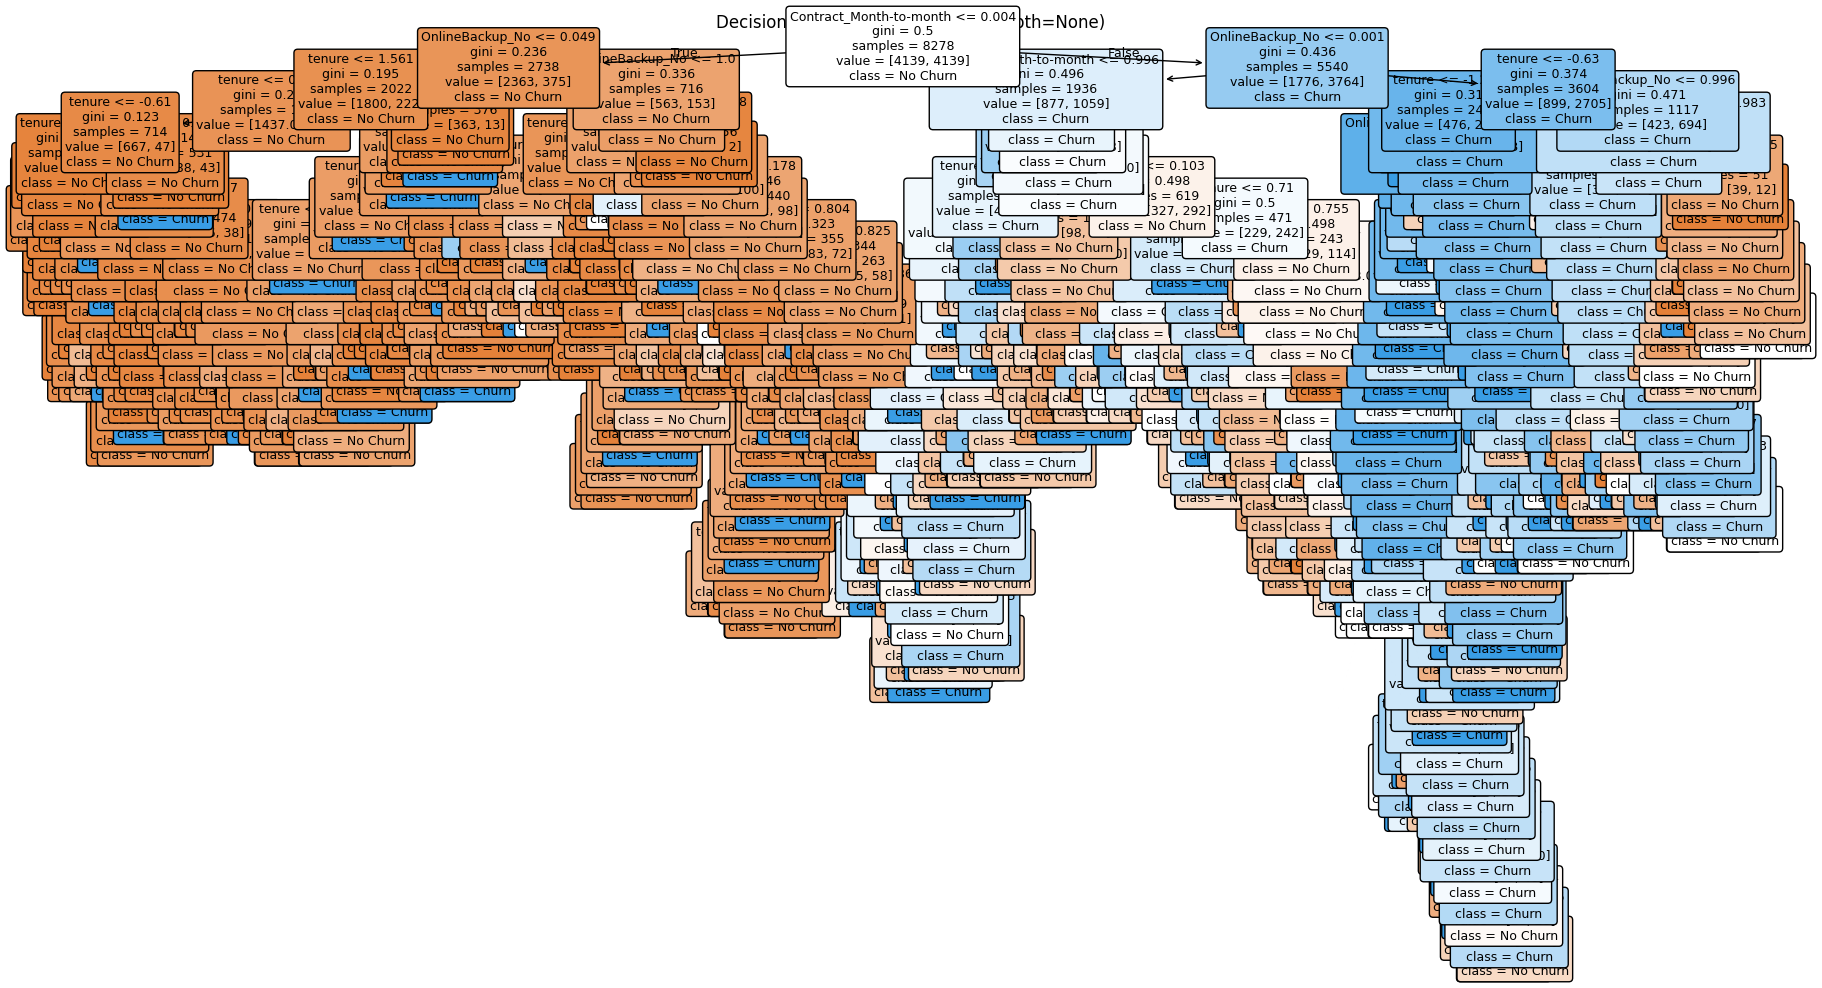

In [43]:
plt.figure(figsize=(22, 12))

plot_tree(
    tree_models[None],
    feature_names=selected_cols,
    class_names=['No Churn', 'Churn'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('Decision Tree Visualization (max_depth=None)')
plt.show()

### Comparison of Classification Models

In [44]:
comparison_df = pd.DataFrame({

    'Model': [
        'KNN',
        'Logistic Regression',
        'Decision Tree (max_depth=3)',
        'Decision Tree (max_depth=5)',
        'Decision Tree (max_depth=10)',
        'Decision Tree (max_depth=None)'
    ],

    'Accuracy': [
        accuracy_score(y_test_final, knn_pred),
        accuracy_score(y_test_final, log_reg_pred),
        *[accuracy_score(y_test_final, tree_predictions[d]) for d in depth_values]
    ],

    'Precision': [
        precision_score(y_test_final, knn_pred),
        precision_score(y_test_final, log_reg_pred),
        *[precision_score(y_test_final, tree_predictions[d]) for d in depth_values]
    ],

    'Recall': [
        recall_score(y_test_final, knn_pred),
        recall_score(y_test_final, log_reg_pred),
        *[recall_score(y_test_final, tree_predictions[d]) for d in depth_values]
    ],

    'F1 Score': [
        f1_score(y_test_final, knn_pred),
        f1_score(y_test_final, log_reg_pred),
        *[f1_score(y_test_final, tree_predictions[d]) for d in depth_values]
    ]

})

comparison_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.7289,0.4859,0.3690,0.4195
1,Logistic Regression,0.6707,0.4384,0.8556,0.5797
2,Decision Tree (max_depth=3),0.6529,0.4256,0.8797,0.5737
3,Decision Tree (max_depth=5),0.6565,0.4274,0.8663,0.5724
4,Decision Tree (max_depth=10),0.6828,0.4423,0.7487,0.5561
5,Decision Tree (max_depth=None),0.7622,0.5582,0.5000,0.5275


### Model Comparison

KNN: 73.13% accuracy, but low recall (45.19%) missed most churners.

Logistic Regression: Highest F1-score (57.33%), giving the best precision-recall balance.

Decision Tree (max_depth=3): Highest recall (87.17%) with lower precision, catching the most churners.

Decision Tree (max_depth=None): Highest accuracy (73.99%) and precision (51.18%), but low recall (46.26%).

Conclusion: Choose Logistic Regression for overall balance, or Decision Tree (max_depth=3) to catch the maximum number of at-risk customers.

Effect of Maximum Depth on Decision Tree
Higher maximum depth increases model complexity and overfitting risk:

max_depth=3: Highest recall (87.17%), lowest accuracy (63.61%).

max_depth=5: Accuracy rises slightly (64.04%), recall dips slightly (85.83%).

max_depth=10: Accuracy rises to 69.30%, recall drops to 66.58%.

max_depth=None: Highest accuracy (73.99%), lowest recall (46.26%).

Does greater depth always improve performance?

No. Deeper trees risk overfitting and do not improve every metric on unseen data. Accuracy rose with depth here, while recall fell—so pick depth based on your target metric and business goal.